# Práctica 1: Predicción Multiclase de Riesgo Cardiovascular en Población Adulta

## Planteamiento del problema

Las enfermedades cardiovasculares continúan siendo una de las mayores amenazas para la salud pública global y una de las principales causas de morbimortalidad a nivel mundial. Para combatir este problema, la detección temprana y la estratificación precisa del nivel de riesgo individual son pilares esenciales que permiten aplicar intervenciones preventivas adaptadas a cada paciente y optimizar la gestión de los recursos en los sistemas de salud.

Conscientes de esta necesidad, el equipo médico e investigador del **Hospital Morales Meseguer** ha puesto en marcha un proyecto estratégico orientado al desarrollo de herramientas predictivas de vanguardia. La iniciativa nace con el objetivo de ofrecer una solución integral basada en datos clínicos que transforme la evaluación del riesgo cardiovascular en la práctica médica diaria, mejorando directamente el diagnóstico y el seguimiento del paciente. Para ello, el equipo médico pone a disposición de este proyecto una cohorte clínica con 2.254 registros de pacientes y 28 variables sociodemográficas, clínicas, analíticas y de estilo de vida para clasificar a los pacientes en tres niveles de riesgo cardiovascular (**Clase 0: Bajo Riesgo, Clase 1: Riesgo Moderado y Clase 2: Alto Riesgo**).

## Requisitos técnicos e instalación de librerías necesarias

Para reproducir el proyecto se recomienda crear un entorno virtual e instalar las versiones exactas de `requirements.txt`:

```bash
python -m venv .venv
# Windows: .venv\Scripts\activate   |   Linux/Mac: source .venv/bin/activate
pip install -r requirements.txt
```

## Implementación

### Librerías a importar

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Semilla para que todo sea reproducible
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

### Carga de la base de datos (csv)

In [2]:
# Cargamos el dataset 
original_dataset = pd.read_csv("enfermedad_cardiovascular.csv", encoding="UTF-8")

print(f"Dimensiones: {original_dataset.shape}")
# Mostramos las primeras 5 filas
original_dataset.head()

Dimensiones: (2254, 28)


,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,6.5,7.6,9.4,3.80,3.70,69.5,3.3,110.4,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,5.0,8.7,0.0,4.07,4.67,87.5,5.6,88.4,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,8.7,9.7,20.8,3.39,7.15,100.6,1.2,123.8,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,5.7,5.6,10.0,0.75,4.81,92.0,1.5,93.3,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,6.7,-4.9,5.5,NaN,10.13,93.7,5.7,91.0,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0


### 1. Análisis exploratorio de datos e identificación de problemáticas

#### 1.1. Estructura general del dataset

Separamos las variables por tipo según el diccionario del enunciado: numéricas continuas, binarias (0/1) y nominales. Trabajamos sobre una copia para no tocar el dataset original.

In [3]:
df = original_dataset.copy()

target = "riesgo_cardiovascular"
vars_binarias = ["fumador_actual", "hipertension_previa", "diabetes_mellitus",
                 "tratamiento_estatinas", "uso_antihipertensivos"]
vars_categoricas = ["tipo_alimentacion", "nivel_actividad", "antecedentes_familiares_tipo"]
vars_numericas = [c for c in df.columns if c not in vars_binarias + vars_categoricas + [target]]

print(f"Numéricas: {len(vars_numericas)} | Binarias: {len(vars_binarias)} | Categóricas: {len(vars_categoricas)}")
df.info()

Numéricas: 19 | Binarias: 5 | Categóricas: 3
<class 'pandas.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                

#### 1.2. Variable objetivo

,n,%
riesgo_cardiovascular,,
0,1127,50.0
1,676,30.0
2,451,20.0


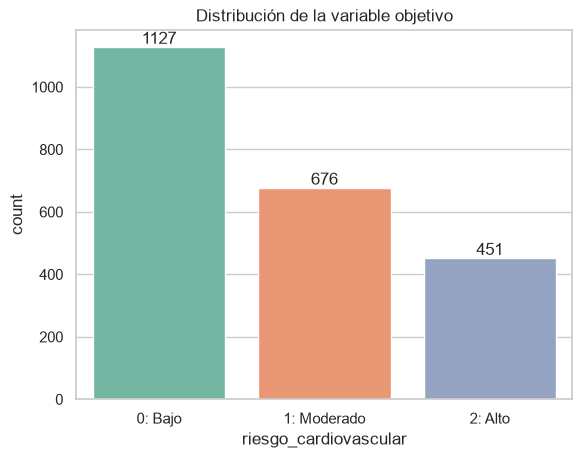

Ratio clase mayoritaria / minoritaria: 2.50


In [4]:
conteo = df[target].value_counts().sort_index()
porcentaje = (conteo / len(df) * 100).round(1)
display(pd.DataFrame({"n": conteo, "%": porcentaje}))

ax = sns.countplot(x=target, data=df, hue=target, palette="Set2", legend=False)
ax.set_xticks([0, 1, 2], ["0: Bajo", "1: Moderado", "2: Alto"])
ax.set_title("Distribución de la variable objetivo")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

print(f"Ratio clase mayoritaria / minoritaria: {conteo.max() / conteo.min():.2f}")

**Observación:** las clases están desbalanceadas (≈50% / 30% / 20%). La clase de alto riesgo, que es la más importante desde el punto de vista clínico, es la minoritaria. Esto habrá que tenerlo en cuenta en la partición (estratificada), en las métricas (no basta con accuracy) y en el preprocesado.

#### 1.3. Valores nulos y duplicados

In [5]:
nulos = df.isna().sum()
nulos = pd.DataFrame({"nulos": nulos, "%": (nulos / len(df) * 100).round(2)})
display(nulos[nulos["nulos"] > 0])

print(f"Filas con al menos un nulo: {df.isna().any(axis=1).sum()} ({df.isna().any(axis=1).mean() * 100:.1f}%)")
print(f"Filas duplicadas: {df.duplicated().sum()}")

,nulos,%
colesterol_ldl,135,5.99
glucosa_ayunas,112,4.97
horas_sueno_diarias,180,7.99
proteina_c_reactiva,157,6.97


Filas con al menos un nulo: 533 (23.6%)
Filas duplicadas: 0


In [6]:
# ¿Los nulos dependen de la clase? Si fuera así no serían aleatorios
cols_nulos = nulos[nulos["nulos"] > 0].index
(df[cols_nulos].isna().groupby(df[target]).mean() * 100).round(2)

,colesterol_ldl,glucosa_ayunas,horas_sueno_diarias,proteina_c_reactiva
riesgo_cardiovascular,,,,
0,6.39,4.44,8.25,8.16
1,6.07,4.59,7.69,5.77
2,4.88,6.87,7.76,5.76


**Observación:** hay 4 variables con nulos (`colesterol_ldl`, `glucosa_ayunas`, `horas_sueno_diarias` y `proteina_c_reactiva`), entre un 5% y un 8% en cada una. En total afectan a casi una cuarta parte de las filas, así que eliminarlas no es buena opción. El porcentaje de nulos es parecido en las tres clases, lo que apunta a que faltan de forma aleatoria (MCAR/MAR), por lo que tiene sentido imputar. No hay filas duplicadas.

#### 1.4. Estadísticos descriptivos

In [7]:
desc = df[vars_numericas].describe().T
desc["skew"] = df[vars_numericas].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
edad,2254.0,56.69,14.45,9.80,47.20,56.90,66.47,103.50,-0.03
presion_sistolica,2254.0,132.32,26.93,52.20,115.30,129.65,143.90,231.36,1.29
presion_diastolica,2254.0,82.17,13.08,30.80,73.60,82.10,91.10,122.50,-0.03
colesterol_total,2254.0,228.13,62.73,61.10,188.20,221.20,252.50,448.59,1.29
colesterol_hdl,2254.0,47.23,15.99,-8.80,36.70,47.30,58.20,106.30,-0.00
colesterol_ldl,2119.0,135.64,36.73,6.10,111.40,135.50,161.40,266.70,-0.05
trigliceridos,2254.0,176.66,72.74,-35.70,133.05,170.00,208.10,452.70,1.32
glucosa_ayunas,2142.0,104.11,24.94,32.00,86.30,103.75,120.48,194.00,0.12
indice_masa_corporal,2254.0,28.09,6.47,3.60,23.80,28.00,32.50,50.60,0.01
frecuencia_cardiaca_reposo,2254.0,73.67,12.76,25.80,65.00,73.10,82.30,112.70,-0.03


In [8]:
df[vars_categoricas + vars_binarias].astype(str).describe().T

,count,unique,top,freq
tipo_alimentacion,2254,4,Occidental,881
nivel_actividad,2254,4,Ligeramente activo,695
antecedentes_familiares_tipo,2254,4,Ninguno,1072
fumador_actual,2254,2,0,1659
hipertension_previa,2254,2,0,1427
diabetes_mellitus,2254,2,0,1741
tratamiento_estatinas,2254,2,0,1641
uso_antihipertensivos,2254,2,0,1467


**Observación:** ya en los descriptivos aparecen mínimos y máximos que no tienen sentido clínico (HDL y triglicéridos negativos, consumo de alcohol negativo, IMC de 3.6, edad mínima de 9.8 años en una cohorte de adultos, más de 7 días de ejercicio por semana...). También hay variables con asimetría positiva marcada (`colesterol_total`, `presion_sistolica`, `trigliceridos`, `acido_urico`, `proteina_c_reactiva`). Lo analizamos en detalle más abajo.

#### 1.5. Distribuciones

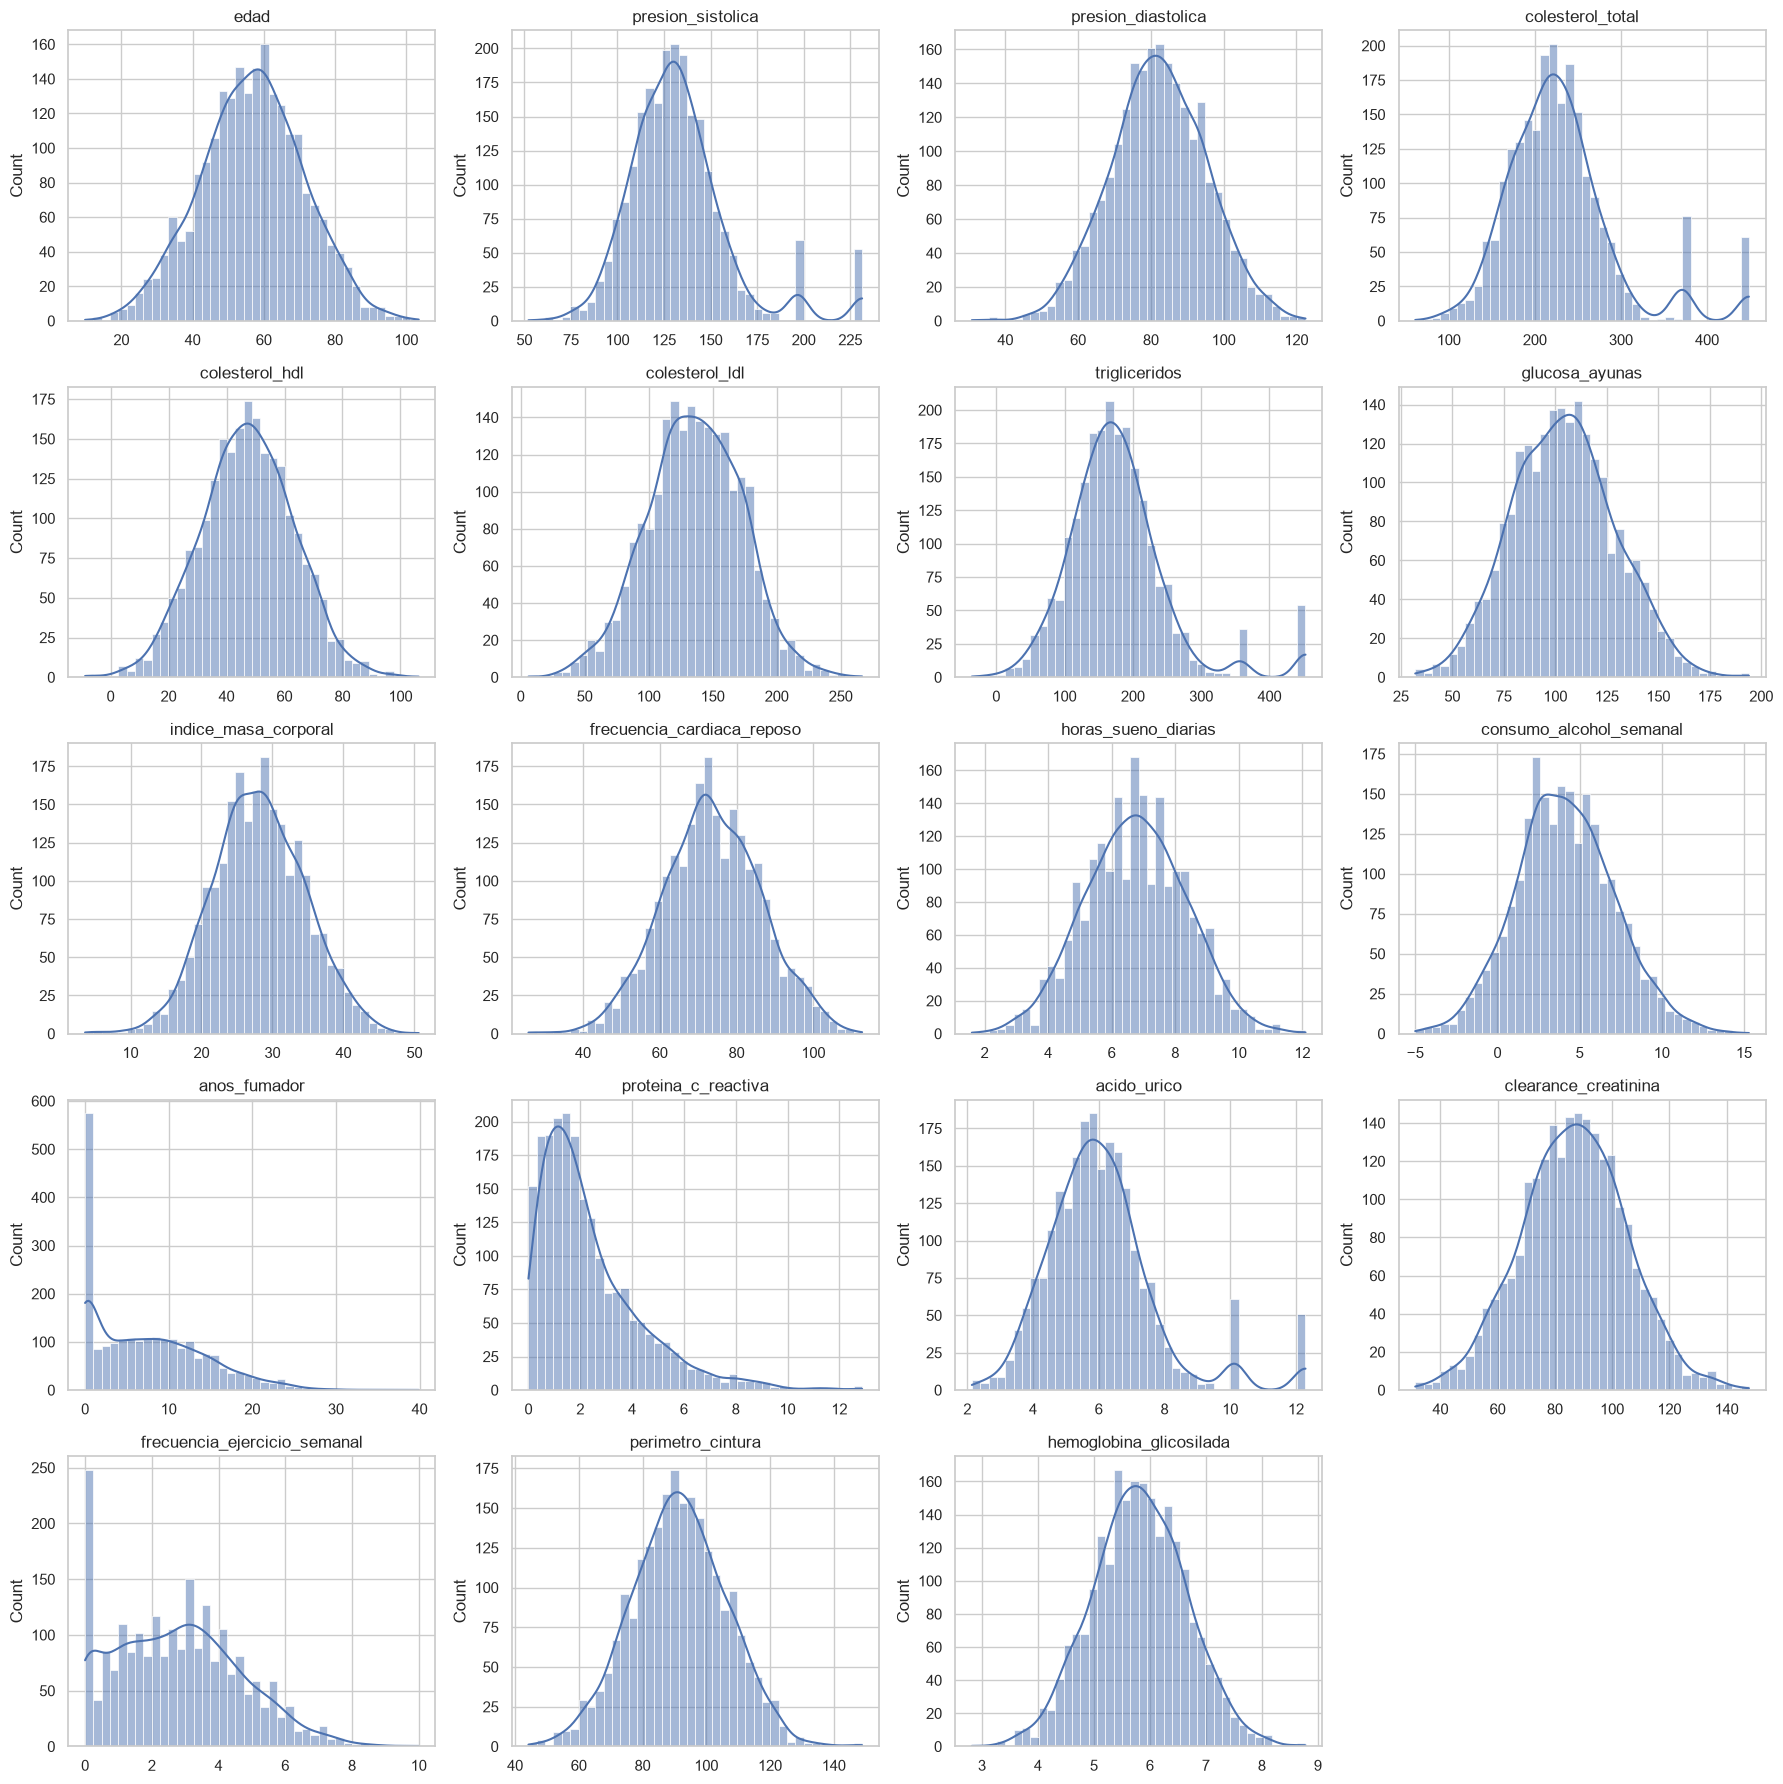

In [9]:
fig, axes = plt.subplots(5, 4, figsize=(18, 18))
for ax, col in zip(axes.flat, vars_numericas):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.flat[len(vars_numericas):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

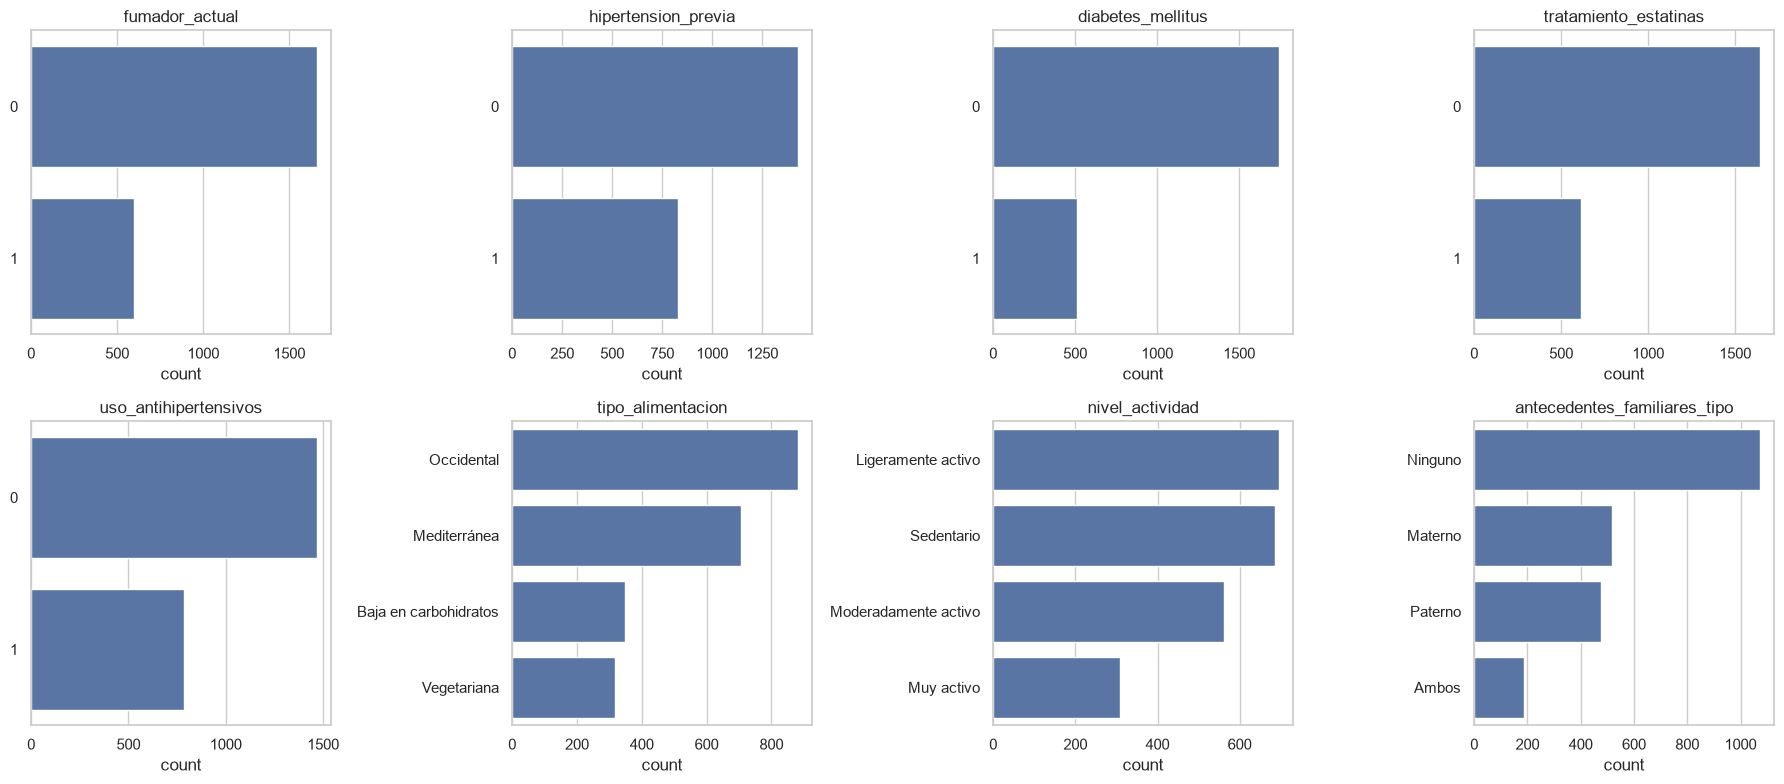

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, vars_binarias + vars_categoricas):
    orden = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=orden, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Observación:** la mayoría de numéricas tienen forma aproximadamente normal, pero en varias se ven **picos aislados en la cola derecha** (sistólica, colesterol total, triglicéridos y ácido úrico). Esos picos no son naturales y los estudiamos en el siguiente apartado. Las categóricas no tienen categorías raras ni mal escritas, aunque algunas están poco representadas (p. ej. `antecedentes_familiares_tipo = Ambos`).

#### 1.6. Valores repetidos anómalos

Comprobamos los valores que más se repiten en cada variable numérica. En una variable continua medida con uno o dos decimales no debería haber un valor que se repita decenas de veces.

In [11]:
repetidos = pd.DataFrame({
    "1er_valor": [df[c].value_counts().index[0] for c in vars_numericas],
    "veces_1": [df[c].value_counts().iloc[0] for c in vars_numericas],
    "2o_valor": [df[c].value_counts().index[1] for c in vars_numericas],
    "veces_2": [df[c].value_counts().iloc[1] for c in vars_numericas],
}, index=vars_numericas).sort_values("veces_2", ascending=False)
repetidos.head(8)

,1er_valor,veces_1,2o_valor,veces_2
frecuencia_ejercicio_semanal,0.00,204,3.00,62
colesterol_total,371.24,74,448.59,61
horas_sueno_diarias,6.80,64,6.70,58
presion_sistolica,196.95,59,231.36,53
acido_urico,10.13,61,12.29,51
consumo_alcohol_semanal,2.60,47,2.40,43
trigliceridos,452.70,54,357.56,36
hemoglobina_glicosilada,5.77,22,5.41,20


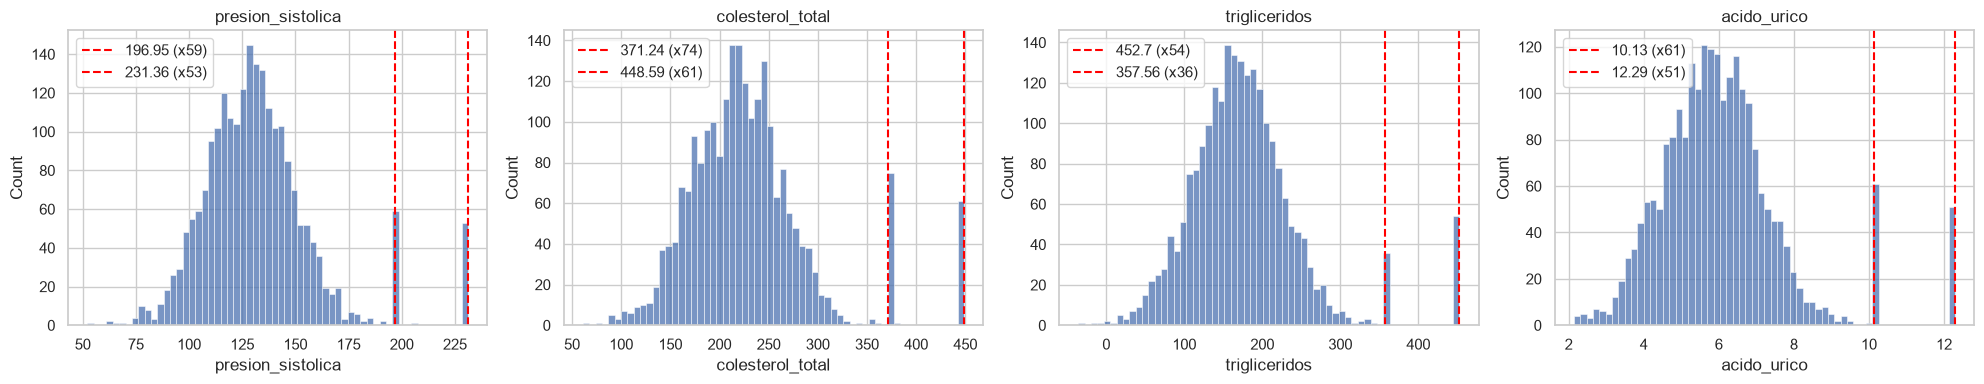

Filas con algún valor repetido anómalo: 420
Reparto por clase (%): {0: 52.6, 1: 27.9, 2: 19.5}


In [12]:
vars_picos = ["presion_sistolica", "colesterol_total", "trigliceridos", "acido_urico"]
picos = {col: df[col].value_counts().index[:2].tolist() for col in vars_picos}

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (col, valores) in zip(axes, picos.items()):
    sns.histplot(df[col], bins=60, ax=ax)
    for v in valores:
        ax.axvline(v, color="red", ls="--", label=f"{v} (x{(df[col] == v).sum()})")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

mask_picos = pd.concat([df[col].isin(v) for col, v in picos.items()], axis=1)
print(f"Filas con algún valor repetido anómalo: {mask_picos.any(axis=1).sum()}")
print("Reparto por clase (%):", (df.loc[mask_picos.any(axis=1), target].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

**Observación:** `presion_sistolica`, `colesterol_total`, `trigliceridos` y `acido_urico` tienen **dos valores exactos que se repiten entre 36 y 74 veces**, los dos en la cola alta de la distribución y separados del resto (p. ej. la sistólica 196.95 y 231.36). No son mediciones reales, parecen outliers inyectados de forma artificial. Afectan a 420 filas y se reparten entre clases casi igual que el dataset completo (≈50/30/20), así que no aportan información sobre el riesgo y solo meten ruido. El pico de `horas_sueno_diarias` en 6.8 coincide con la mediana, lo que podría indicar una imputación previa, aunque es menos claro.

#### 1.7. Valores fuera de rango clínico e incoherencias

Definimos unos rangos fisiológicamente plausibles para población adulta. Son límites amplios, la idea es detectar valores imposibles o casi imposibles, no valores simplemente altos.

In [13]:
rangos = {
    "edad": (18, 100),
    "presion_sistolica": (70, 250),
    "presion_diastolica": (40, 140),
    "colesterol_total": (80, 500),
    "colesterol_hdl": (10, 120),
    "colesterol_ldl": (10, 300),
    "trigliceridos": (20, 1000),
    "glucosa_ayunas": (40, 400),
    "indice_masa_corporal": (12, 70),
    "frecuencia_cardiaca_reposo": (35, 200),
    "horas_sueno_diarias": (2, 16),
    "consumo_alcohol_semanal": (0, 100),
    "anos_fumador": (0, 90),
    "proteina_c_reactiva": (0, 50),
    "acido_urico": (1, 15),
    "clearance_creatinina": (5, 200),
    "frecuencia_ejercicio_semanal": (0, 7),
    "perimetro_cintura": (50, 200),
    "hemoglobina_glicosilada": (3, 20),
}

fuera = pd.DataFrame({
    col: {"min_permitido": lo, "max_permitido": hi,
          "por_debajo": (df[col] < lo).sum(), "por_encima": (df[col] > hi).sum()}
    for col, (lo, hi) in rangos.items()
}).T
fuera["total"] = fuera["por_debajo"] + fuera["por_encima"]
fuera[fuera["total"] > 0].sort_values("total", ascending=False)

,min_permitido,max_permitido,por_debajo,por_encima,total
consumo_alcohol_semanal,0,100,177,0,177
frecuencia_ejercicio_semanal,0,7,0,41,41
colesterol_hdl,10,120,20,0,20
indice_masa_corporal,12,70,13,0,13
trigliceridos,20,1000,10,0,10
glucosa_ayunas,40,400,6,0,6
edad,18,100,4,2,6
perimetro_cintura,50,200,6,0,6
frecuencia_cardiaca_reposo,35,200,5,0,5
presion_sistolica,70,250,4,0,4


In [14]:
# Incoherencias entre variables
incoherencias = {
    "sistolica <= diastolica": (df["presion_sistolica"] <= df["presion_diastolica"]).sum(),
    "LDL > colesterol total": (df["colesterol_ldl"] > df["colesterol_total"]).sum(),
    "HDL + LDL > colesterol total": ((df["colesterol_hdl"] + df["colesterol_ldl"]) > df["colesterol_total"]).sum(),
    "años fumador > edad": (df["anos_fumador"] > df["edad"]).sum(),
}
pd.Series(incoherencias, name="filas")

sistolica <= diastolica          44
LDL > colesterol total          140
HDL + LDL > colesterol total    559
años fumador > edad               1
Name: filas, dtype: int64

In [15]:
# El alcohol negativo es el caso más numeroso, miramos cómo se reparte por clase
neg = df[df["consumo_alcohol_semanal"] < 0]
print(f"Alcohol negativo: {len(neg)} filas")
(neg[target].value_counts(normalize=True).sort_index() * 100).round(1)

Alcohol negativo: 177 filas


riesgo_cardiovascular
0    82.5
1    15.8
2     1.7
Name: proportion, dtype: float64

**Observación:** aparecen valores imposibles (alcohol, HDL o triglicéridos negativos, más de 7 días de ejercicio por semana, IMC < 12, menores de edad en una cohorte adulta...) e incoherencias entre variables (sistólica ≤ diastólica, LDL mayor que el colesterol total). Son errores de registro y habrá que tratarlos como datos faltantes antes de imputar, o recortarlos al rango válido. El caso más numeroso es el consumo de alcohol negativo (177 filas, el 82% de clase 0). Viendo la distribución, parece simplemente la cola baja de la variable (la clase 0 es la que menos bebe), así que lo más razonable es recortar esos valores a 0 en lugar de eliminar filas, que además desbalancearía más las clases. Por otro lado, hay 559 filas donde HDL + LDL supera el colesterol total, lo que confirma que las variables lipídicas tienen bastante ruido.

Los pacientes con `fumador_actual = 0` y `anos_fumador > 0` **no** se consideran error: pueden ser exfumadores.

#### 1.8. Outliers estadísticos (criterio IQR)

In [16]:
q1 = df[vars_numericas].quantile(0.25)
q3 = df[vars_numericas].quantile(0.75)
iqr = q3 - q1
mask_out = (df[vars_numericas] < q1 - 1.5 * iqr) | (df[vars_numericas] > q3 + 1.5 * iqr)

outliers = pd.DataFrame({"n_outliers": mask_out.sum(), "%": (mask_out.mean() * 100).round(2)})
outliers[outliers["n_outliers"] > 0].sort_values("n_outliers", ascending=False)

,n_outliers,%
colesterol_total,147,6.52
acido_urico,120,5.32
presion_sistolica,120,5.32
trigliceridos,107,4.75
proteina_c_reactiva,89,3.95
consumo_alcohol_semanal,25,1.11
horas_sueno_diarias,17,0.75
clearance_creatinina,16,0.71
presion_diastolica,16,0.71
perimetro_cintura,15,0.67


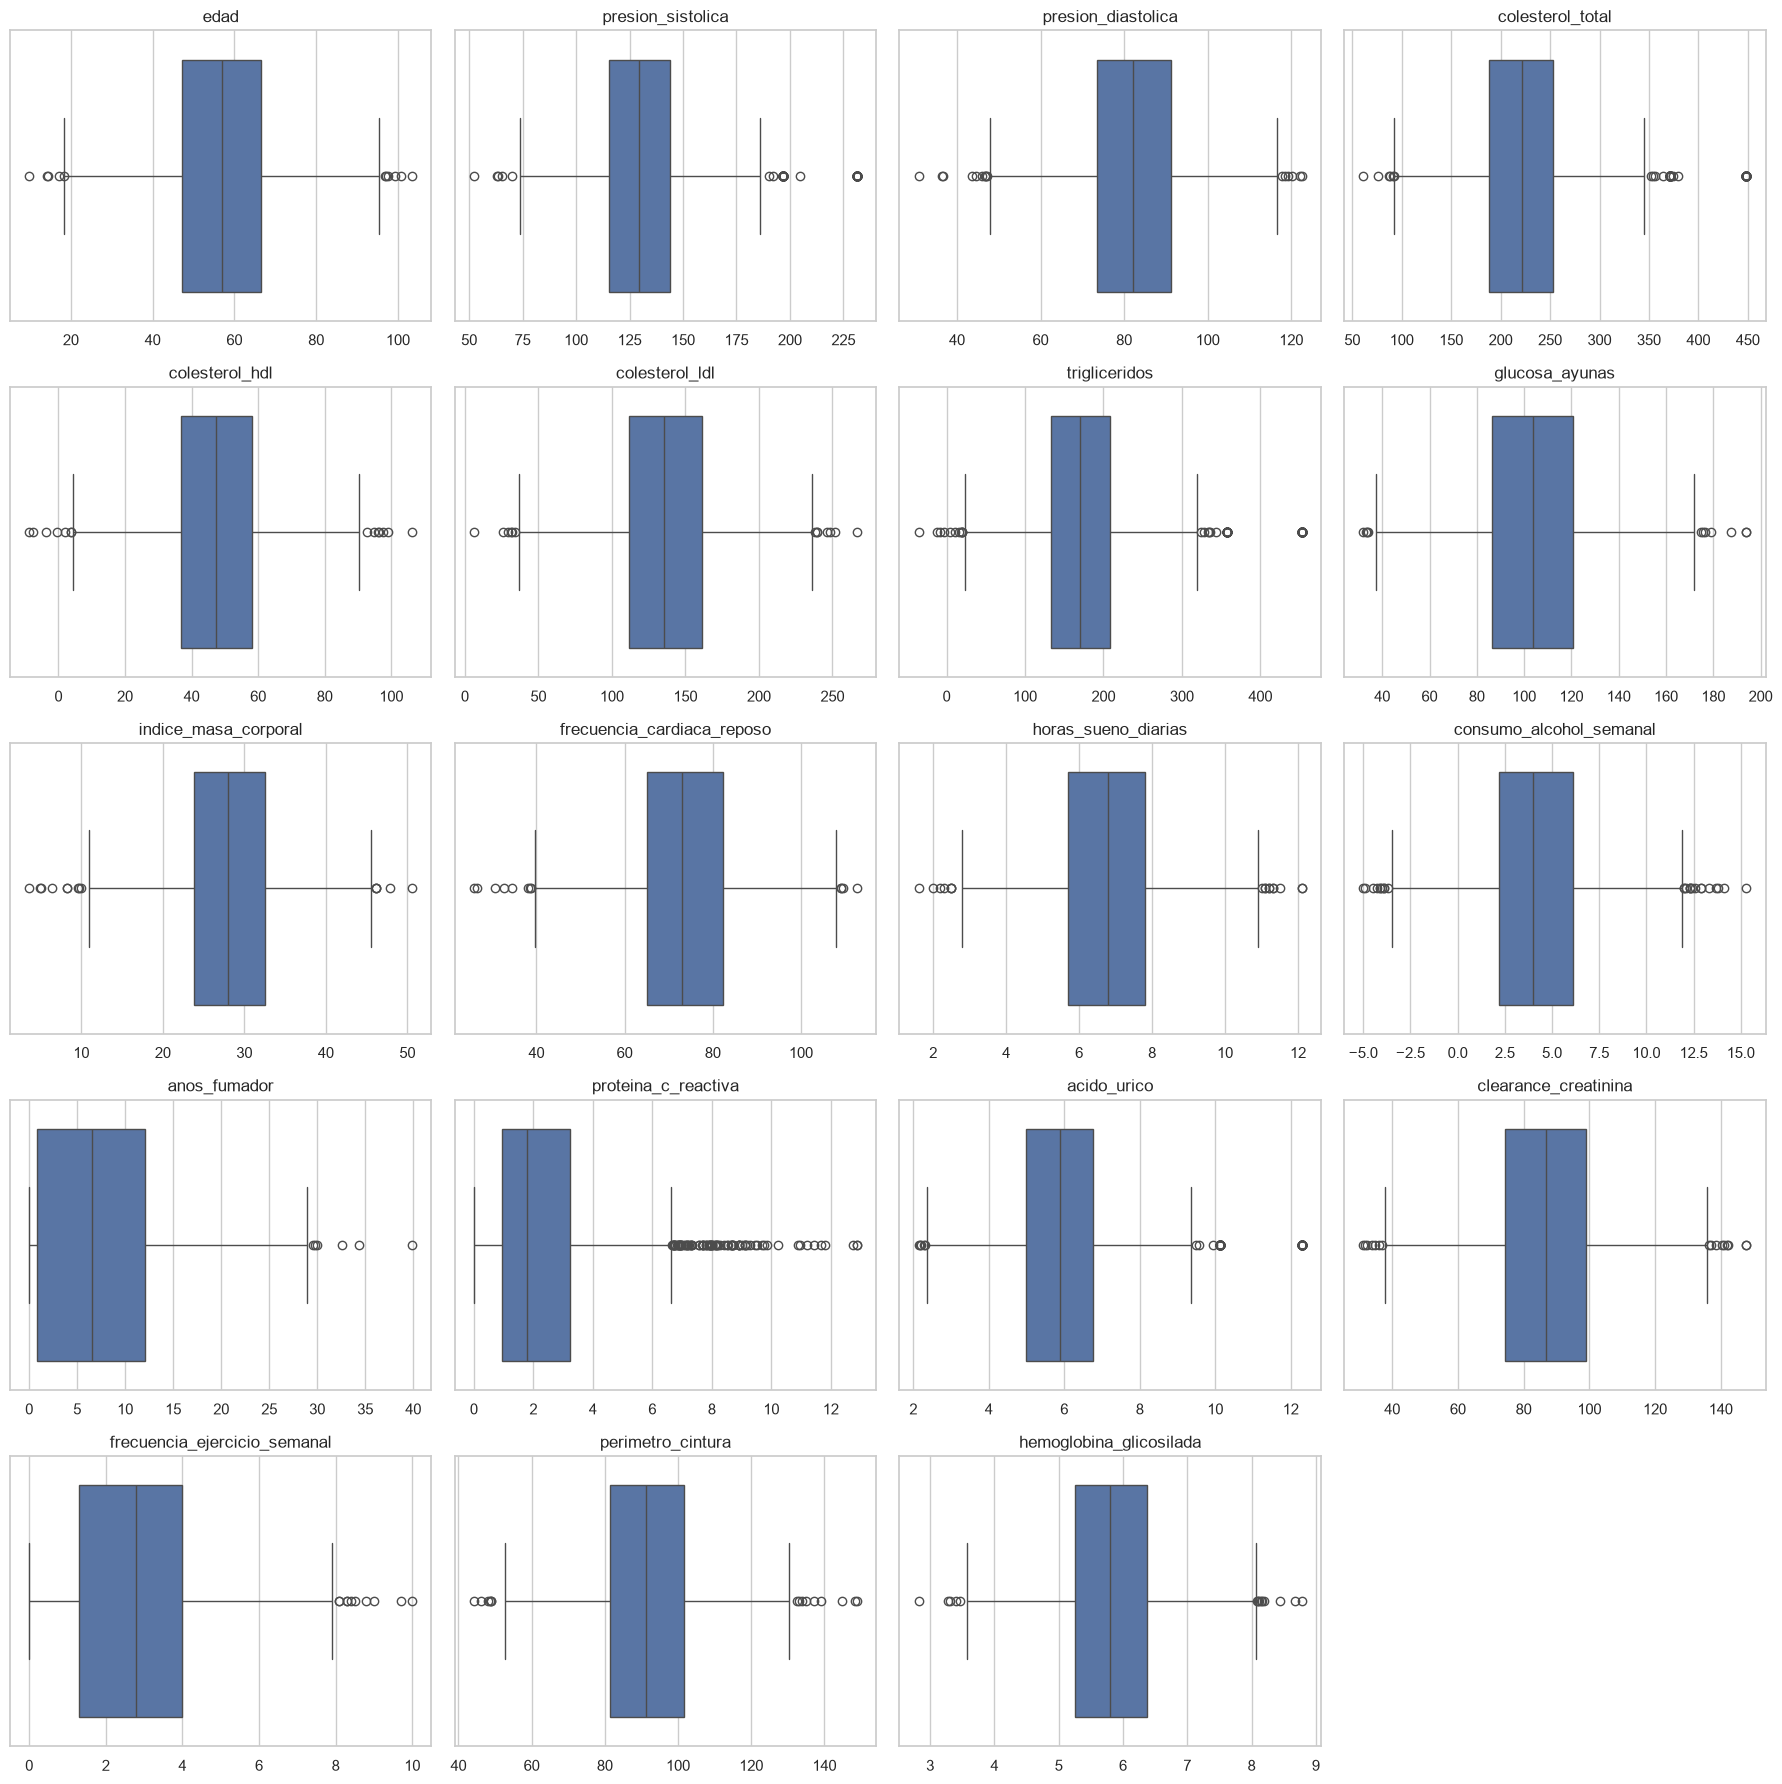

In [17]:
fig, axes = plt.subplots(5, 4, figsize=(18, 18))
for ax, col in zip(axes.flat, vars_numericas):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.flat[len(vars_numericas):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Observación:** las variables con más outliers son justo las que tienen los valores repetidos anómalos (`colesterol_total`, `acido_urico`, `presion_sistolica`, `trigliceridos`) y `proteina_c_reactiva`, que tiene una cola derecha larga por su naturaleza (es habitual en marcadores inflamatorios). Hay que distinguir entre outliers que son errores y valores altos que sí son clínicamente posibles (un paciente con PCR alta existe), así que no se deberían eliminar sin más. Opciones: recorte por percentiles, transformaciones (log / Yeo-Johnson) o escalado robusto.

#### 1.9. Relación de las variables con el riesgo cardiovascular

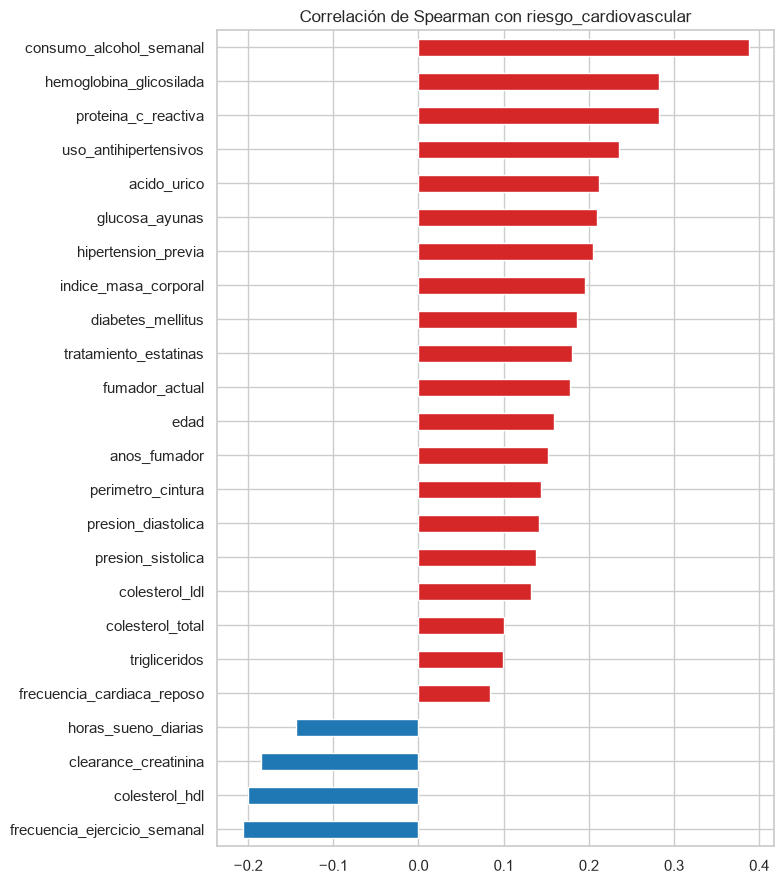

In [18]:
corr_target = df[vars_numericas + vars_binarias + [target]].corr(method="spearman")[target].drop(target)
corr_target = corr_target.sort_values()

plt.figure(figsize=(8, 9))
corr_target.plot.barh(color=np.where(corr_target > 0, "tab:red", "tab:blue"))
plt.title("Correlación de Spearman con riesgo_cardiovascular")
plt.tight_layout()
plt.show()

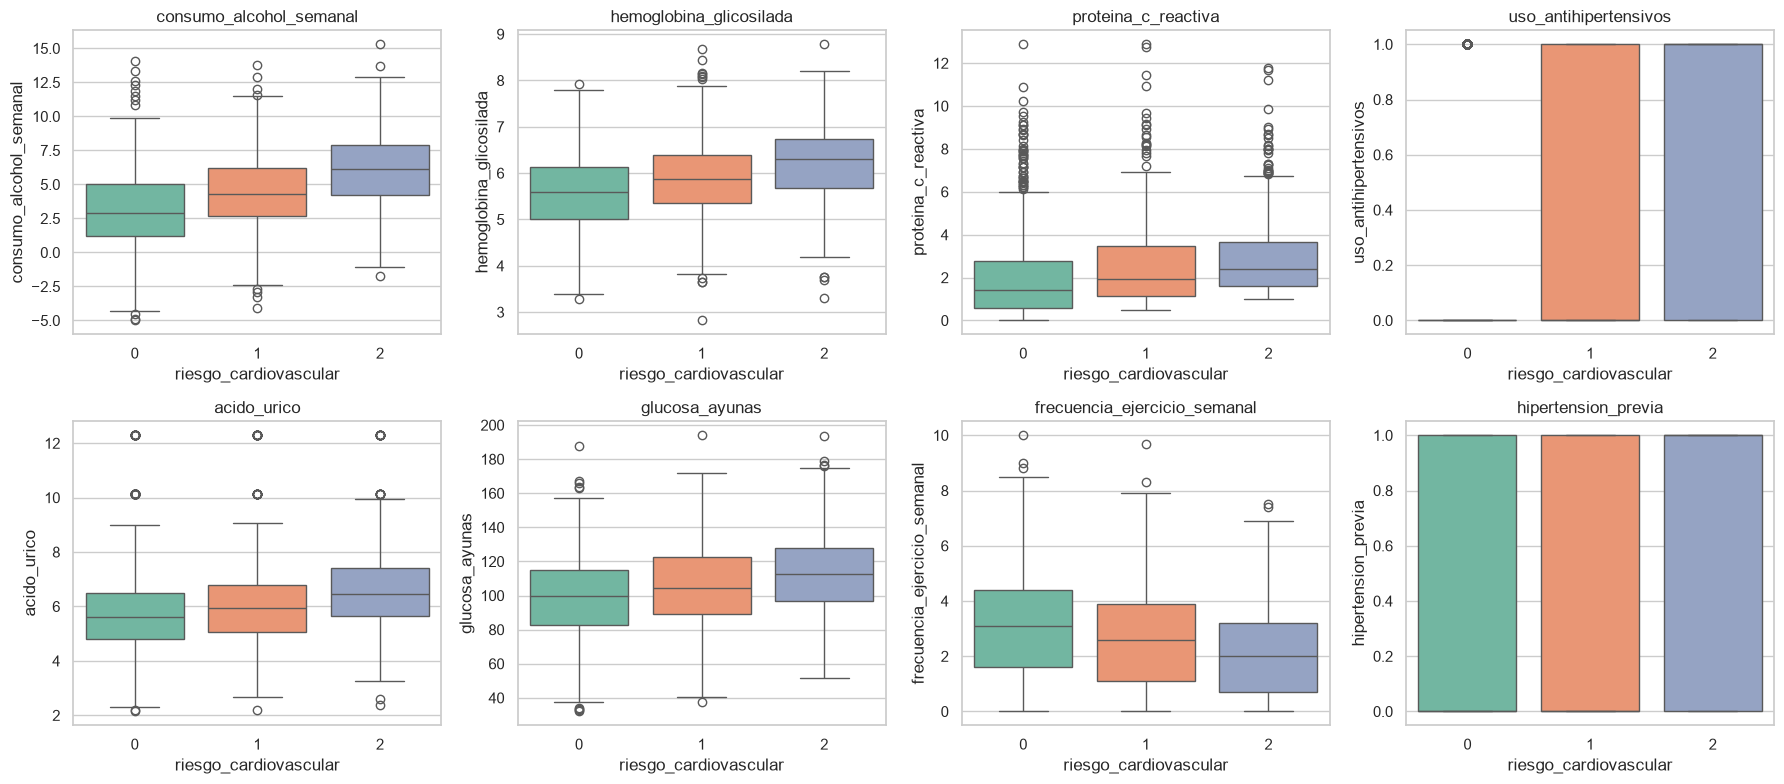

In [19]:
top = corr_target.abs().sort_values(ascending=False).index[:8]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, top):
    sns.boxplot(x=target, y=col, data=df, hue=target, palette="Set2", legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

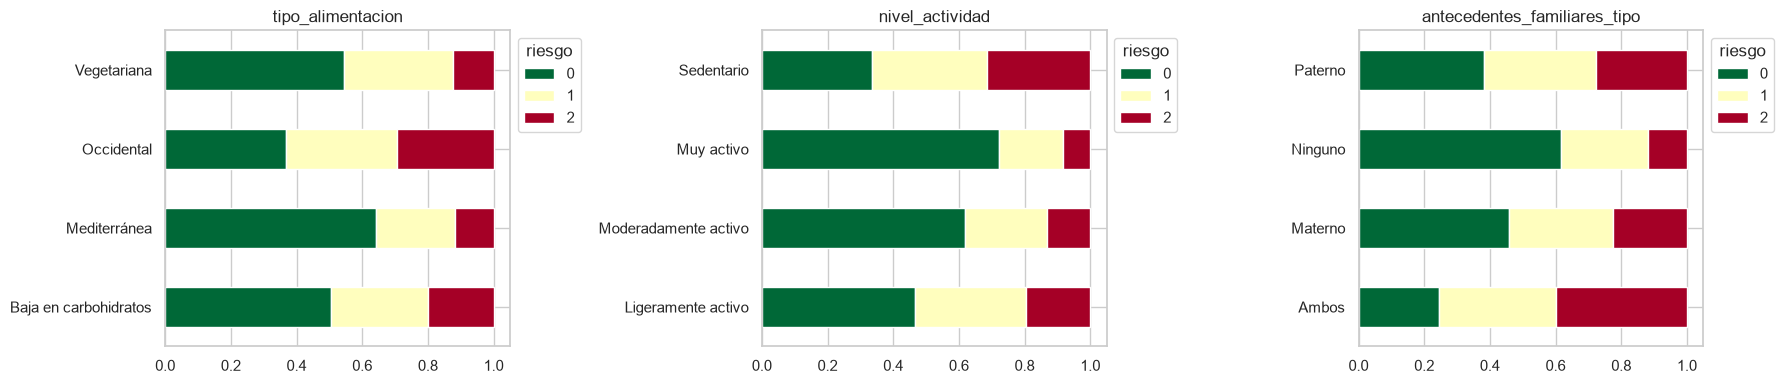

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, vars_categoricas):
    pd.crosstab(df[col], df[target], normalize="index").plot.barh(stacked=True, ax=ax, colormap="RdYlGn_r")
    ax.set_title(col)
    ax.set_ylabel("")
    ax.legend(title="riesgo", bbox_to_anchor=(1.0, 1.0), loc="upper left")
plt.tight_layout()
plt.show()

**Observación:** ninguna variable por sí sola separa bien las clases (las correlaciones de Spearman son bajas o moderadas, la mayor es la del consumo de alcohol con ≈0.39, seguida de HbA1c y PCR con ≈0.28), así que el problema necesitará combinar muchas variables. Las relaciones van en la dirección esperada clínicamente: más riesgo con HbA1c, glucosa, IMC, PCR, hipertensión, diabetes o tabaco, y menos con HDL, ejercicio, horas de sueño y función renal. En las categóricas, la dieta mediterránea, la actividad física y no tener antecedentes familiares se asocian a menor riesgo. `nivel_actividad` tiene un **orden natural**, así que se puede codificar como ordinal; las otras dos son nominales (one-hot).

#### 1.10. Correlación entre variables predictoras

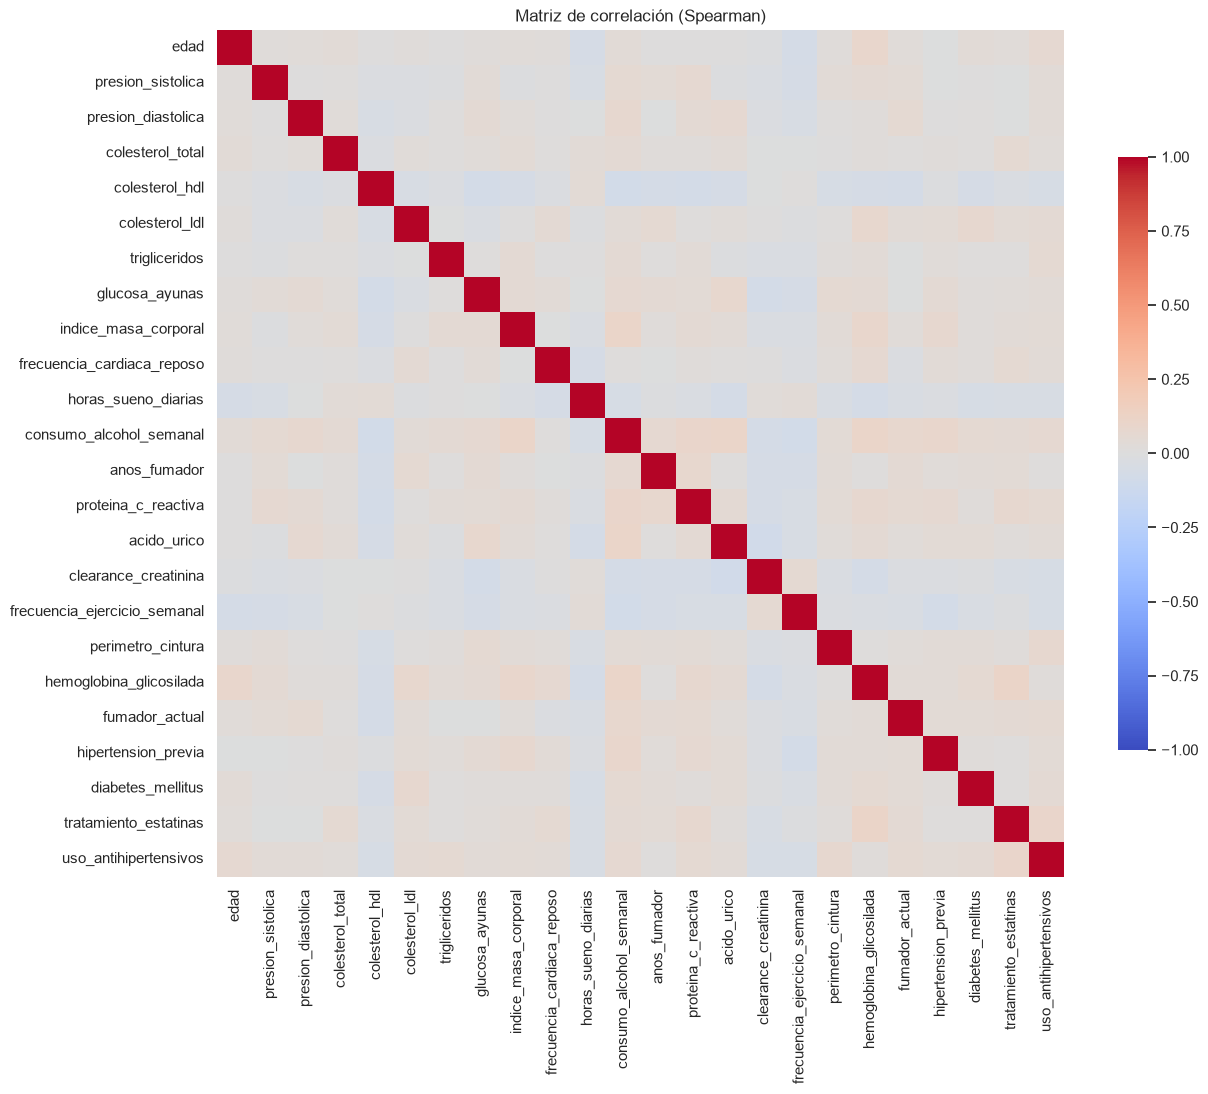

hemoglobina_glicosilada  tratamiento_estatinas      0.111345
consumo_alcohol_semanal  hemoglobina_glicosilada    0.109305
indice_masa_corporal     consumo_alcohol_semanal    0.109184
consumo_alcohol_semanal  acido_urico                0.108531
                         proteina_c_reactiva        0.098291
dtype: float64

In [21]:
corr = df[vars_numericas + vars_binarias].corr(method="spearman")
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7})
plt.title("Matriz de correlación (Spearman)")
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pares.abs().sort_values(ascending=False).head(5)

**Observación:** las correlaciones entre predictoras son muy bajas (ninguna supera 0.15 en valor absoluto), así que no hay problema de multicolinealidad y en principio no hace falta eliminar variables redundantes. Llama la atención que variables que clínicamente deberían ir juntas (colesterol total con LDL, IMC con perímetro de cintura, glucosa con HbA1c) apenas estén correlacionadas, lo que sugiere que el dataset es sintético o tiene bastante ruido.

#### 1.11. Resumen de problemáticas detectadas

| # | Problemática | Variables afectadas | Posible tratamiento (apartado 2) |
|---|---|---|---|
| 1 | **Valores nulos** (5–8% por variable, ~24% de filas) | `colesterol_ldl`, `glucosa_ayunas`, `horas_sueno_diarias`, `proteina_c_reactiva` | Imputación (mediana / KNN / iterativa) dentro del pipeline |
| 2 | **Valores imposibles e incoherencias** | alcohol, HDL, triglicéridos, IMC, edad, ejercicio, PA, LDL... | Pasarlos a NaN e imputarlos, o recortarlos al rango clínico |
| 3 | **Valores repetidos anómalos (outliers inyectados)** y colas largas | `presion_sistolica`, `colesterol_total`, `trigliceridos`, `acido_urico` | Pasarlos a NaN e imputar, o recorte por percentiles / transformación |
| 4 | **Asimetría y escalas muy distintas** | PCR, triglicéridos, colesterol total... | Escalado (Standard / Robust) y transformación (Yeo-Johnson) |
| 5 | **Desbalance de clases** (50/30/20) | `riesgo_cardiovascular` | Partición estratificada, `class_weight`, SMOTE (solo en train) |
| 6 | **Variables categóricas** | `tipo_alimentacion`, `nivel_actividad`, `antecedentes_familiares_tipo` | One-hot para nominales, ordinal para `nivel_actividad` |

Todas las transformaciones que aprendan algo de los datos (imputación, escalado, SMOTE...) se tendrán que ajustar **solo con los datos de entrenamiento** dentro de un `Pipeline` para evitar data leakage.

### 2. Preprocesamiento de datos

### 3. Modelos

### 4. Estrategia de evaluación y métricas de rendimiento

### 5. Test estadísticos

## Conclusiones